In [79]:
import pandas as pd
import numpy as np
from matplotlib.ticker import MaxNLocator
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score


In [80]:
df = pd.read_pickle("./data_features_clustering")
df.columns

Index(['Unnamed: 0', 'id', 'connectionTime', 'disconnectTime',
       'doneChargingTime', 'kWhDelivered', 'sessionID', 'siteID', 'spaceID',
       'stationID', 'timezone', 'userID', 'userInputs', 'endChargingTime',
       'chargingDurationMin', 'blockingDurationMin', 'charging_time_minutes',
       'energy_rate_kW', 'connection_hour', 'disconnect_hour',
       'connection_hour_sin', 'connection_hour_cos', 'disconnect_hour_sin',
       'disconnect_hour_cos', 'connection_isWeekday', 'isRegisteredUser'],
      dtype='object')

In [81]:
def scale_features(features:pd.DataFrame, scaler:StandardScaler):
    non_binary_cols = features.columns[features.nunique() > 2]
    scaled_features = features.copy()
    scaled_features[non_binary_cols] = scaler.fit_transform(features[non_binary_cols])
    return scaled_features

def plot_elbow_graph(features:pd.DataFrame, range:range):
    inertia = []
    K = range
    for k in K:
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(features)
        inertia.append(kmeans.inertia_)

    plt.figure(figsize=(8, 5))
    plt.plot(K, inertia, "bo-", markersize=8)
    plt.title("Elbow Plot for Optimal Number of Clusters")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia")
    plt.grid(True)
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.show()


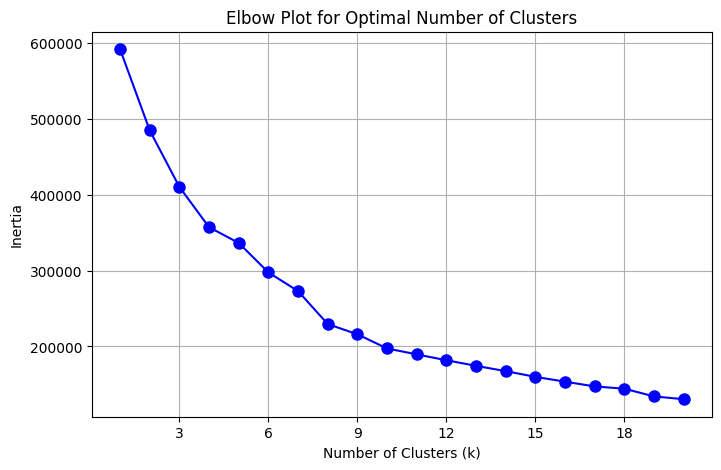

In [82]:
scaler = StandardScaler()
features = df.drop(columns=["Unnamed: 0", "id", "connectionTime", "disconnectTime", "doneChargingTime", "sessionID", "siteID", "spaceID",
                    "stationID", 'timezone', 'userID', 'userInputs', 'endChargingTime', 'connection_hour', 'disconnect_hour'])
scaled_features = scale_features(features, scaler)
plot_elbow_graph(scaled_features, range(1, 21))

In [83]:
optimal_k = 8  # Chosen based on the elbow plot
kmeans = KMeans(n_clusters=optimal_k, random_state=69)
df['Cluster'] = kmeans.fit_predict(scaled_features)

In [84]:
def evaluate_kmeans(kmeans:KMeans, features:pd.DataFrame):
    # Get number of entries

    cluster_labels = kmeans.labels_

    cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()

    print("Number of entries in each cluster:")
    print(cluster_counts)

    # Silhouette Score
    silhouette = silhouette_score(features, kmeans.labels_)
    print(f"Silhouette Score: {silhouette}")

    # Davies-Bouldin Index
    dbi = davies_bouldin_score(features, kmeans.labels_)
    print(f"Davies-Bouldin Index: {dbi}")

In [85]:
evaluate_kmeans(kmeans, scaled_features)

Number of entries in each cluster:
0    17306
1    12156
2    14867
3     6218
4     1573
5    11600
6        4
7       97
Name: count, dtype: int64
Silhouette Score: 0.29317117462539716
Davies-Bouldin Index: 0.983969412379674


In [86]:
# Run KMeans multiple times with different random states

def run_random_states(n:int, n_clusters:int, features:pd.DataFrame):
    sil_scores = []
    dbi_scores = []
    kmeans_models = []

    for i in range(n):
        kmeans = KMeans(n_clusters, random_state=i)  # Change the number of clusters if needed
        kmeans.fit(features)
        
        # Compute the Silhouette Score for the current model
        score = silhouette_score(features, kmeans.labels_)
        dbi = davies_bouldin_score(features, kmeans.labels_)
        sil_scores.append(score)
        dbi_scores.append(dbi)
        kmeans_models.append(kmeans)


    # Output the best silhouette score and its corresponding model
    print(f"Best Silhouette Score: {sil_scores[np.argmax(sil_scores)]}")
    print(f"Best DBI Score: {dbi_scores[np.argmin(dbi_scores)]}")

    return kmeans_models, sil_scores, dbi_scores


In [87]:
kmeans_models, sil_scores, dbi_scores = run_random_states(10,8,scaled_features)

Best Silhouette Score: 0.2931476736800817
Best DBI Score: 0.9636545587715132


In [88]:
def plot_cluster_centers(kmeans:KMeans, features:pd.DataFrame):
    # Get Cluster Centers (in scaled space)
    cluster_centers_scaled = kmeans.cluster_centers_

    # Create new df
    cluster_centers_original = pd.DataFrame(cluster_centers_scaled, columns=scaled_features.columns)

    # Replace the scaled columns with their inverse-transformed values
    non_binary_cols = features.columns[features.nunique() > 2]
    cluster_centers_original[non_binary_cols] = scaler.inverse_transform(cluster_centers_scaled[:, :len(non_binary_cols)])

    # Assuming `cluster_centers_original` is a DataFrame with cluster centers in the original scale
    features = cluster_centers_original.columns
    num_features = len(features)

    # Create subplots (one for each feature)
    fig, axes = plt.subplots(num_features, 1, figsize=(10, 4 * num_features), sharex=True)

    # Plot each feature
    for i, feature in enumerate(features):
        axes[i].bar(cluster_centers_original.index, cluster_centers_original[feature], color='skyblue')
        axes[i].set_title(f'Feature: {feature}', fontsize=12)
        axes[i].set_ylabel('Value')
        axes[i].grid(True, axis='y')

    # Set x-axis labels only on the last subplot
    axes[-1].set_xlabel('Clusters')

    # Adjust layout for readability
    plt.tight_layout()
    plt.show()

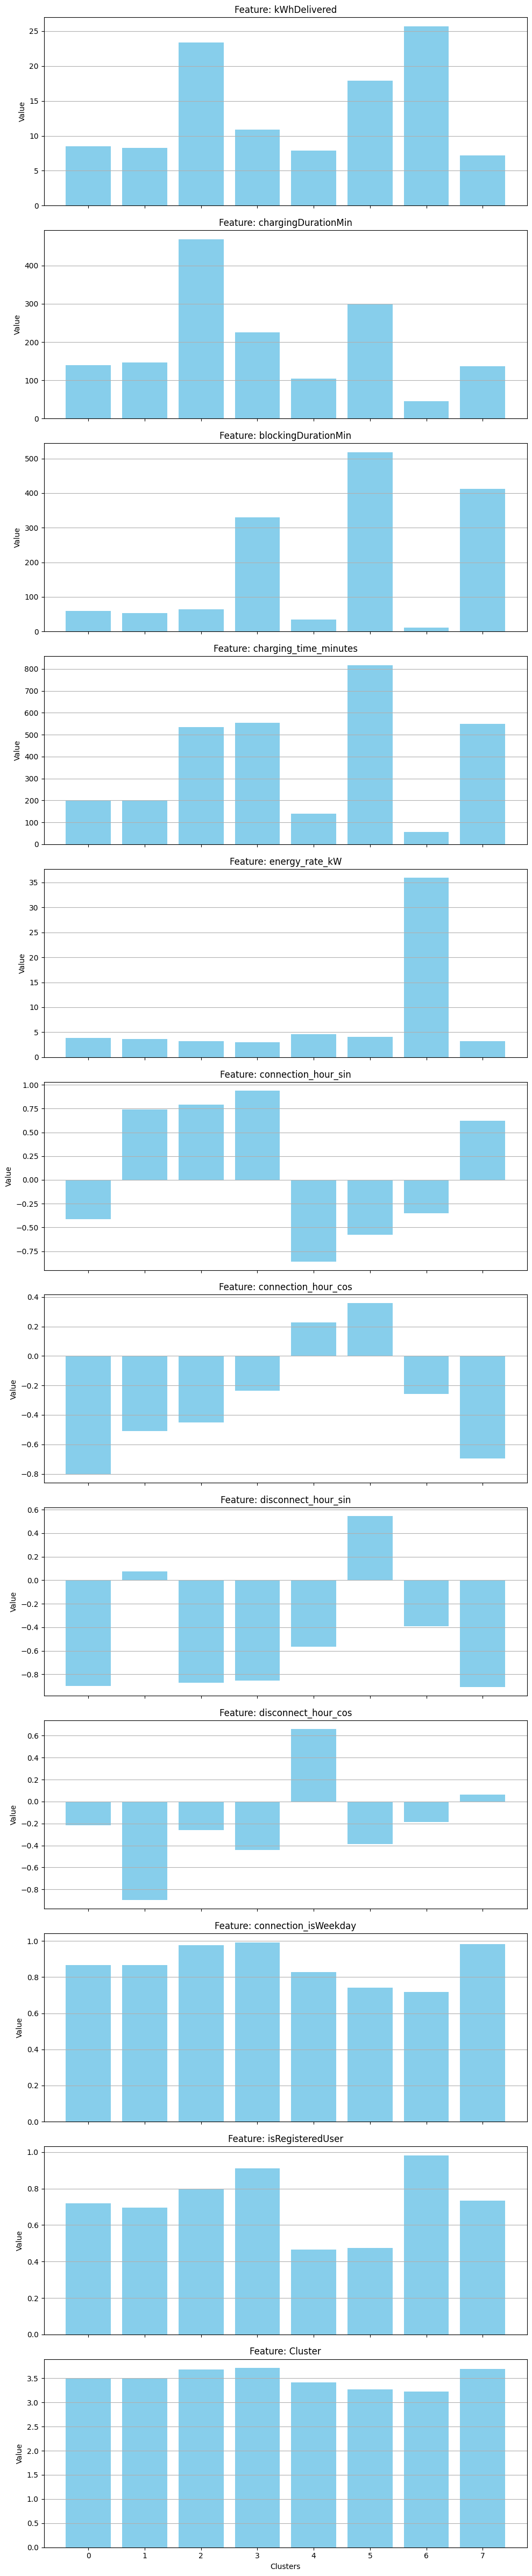

In [96]:
plot_cluster_centers(kmeans,features)

In [90]:
outliers = df[df["Cluster"].isin([6,7])]
pd.to_pickle(outliers, "./clustering_outliers")

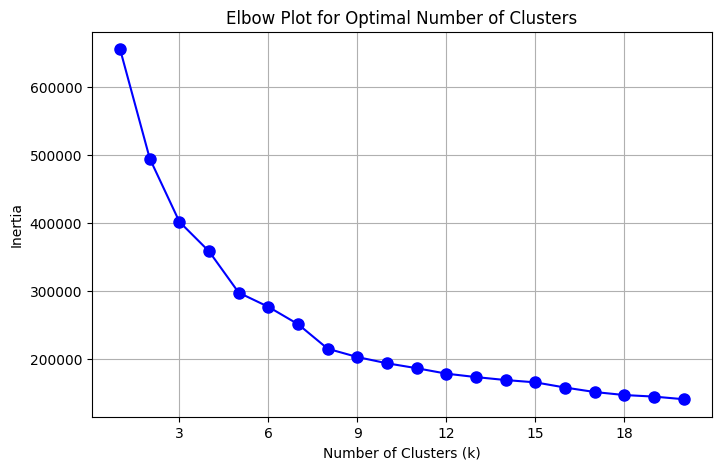

In [91]:
df = df[~df["Cluster"].isin([6, 7])]
scaler = StandardScaler()
features = df.drop(columns=["Unnamed: 0", "id", "connectionTime", "disconnectTime", "doneChargingTime", "sessionID", "siteID", "spaceID",
                    "stationID", 'timezone', 'userID', 'userInputs', 'endChargingTime', 'connection_hour', 'disconnect_hour'])
scaled_features = scale_features(features, scaler)
plot_elbow_graph(scaled_features, range(1, 21))

In [92]:
optimal_k = 8  # Chosen based on the elbow plot
kmeans = KMeans(n_clusters=optimal_k, random_state=69)
df['Cluster'] = kmeans.fit_predict(scaled_features)

evaluate_kmeans(kmeans, scaled_features)

Number of entries in each cluster:
0    14272
1    11379
2    11208
3    10011
4     5879
5     1523
6      847
7     8601
Name: count, dtype: int64
Silhouette Score: 0.285910225947642
Davies-Bouldin Index: 1.1507626723813789


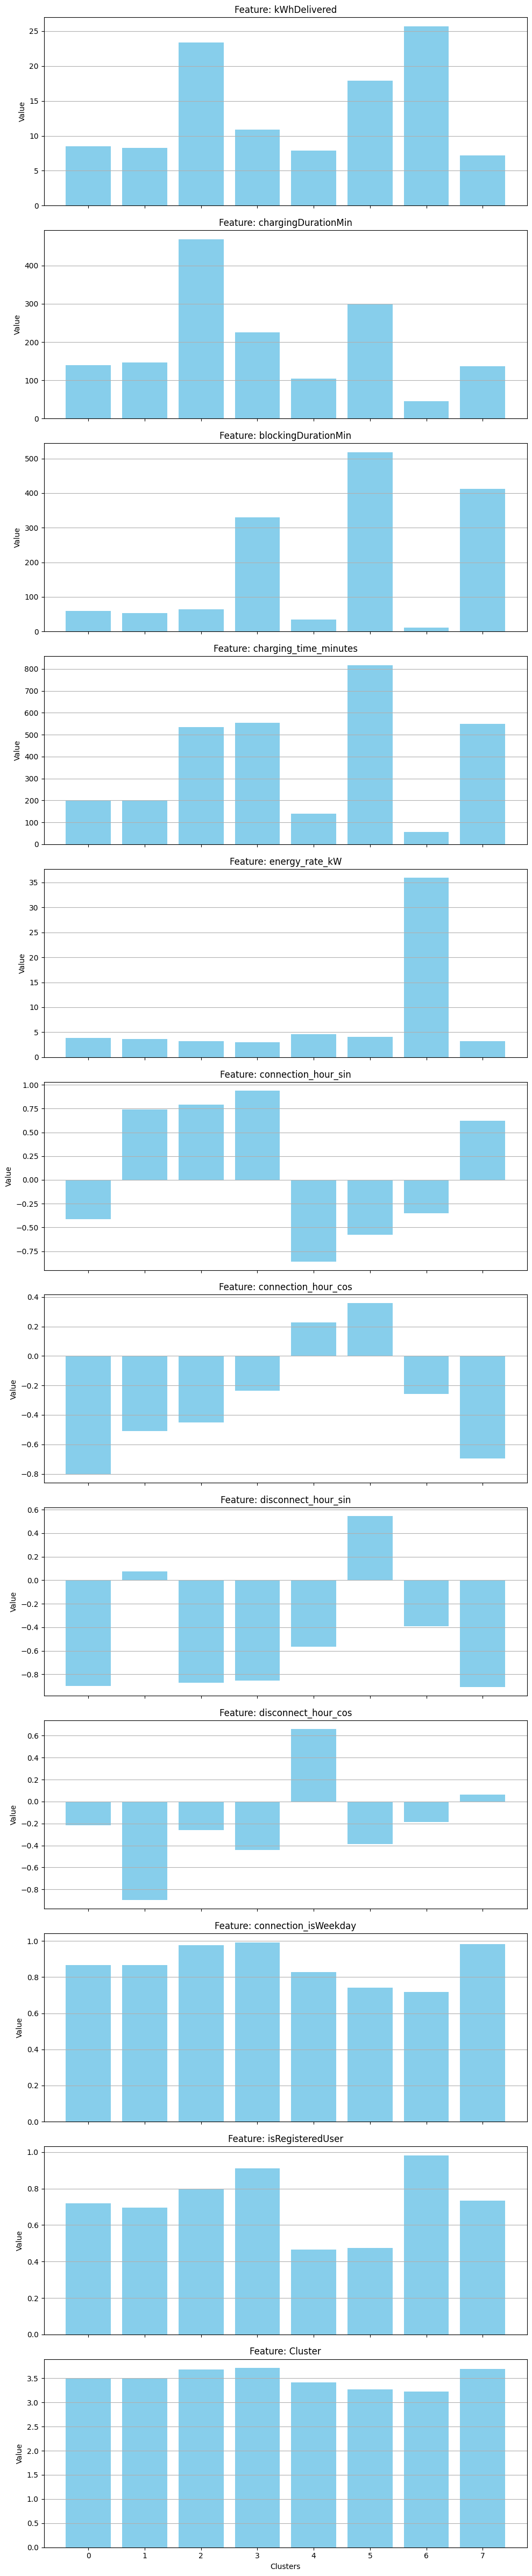

In [97]:
plot_cluster_centers(kmeans,features)

In [94]:
kmeans_models2, sil_scores2, dbi_scores2 = run_random_states(10,8,scaled_features)

Best Silhouette Score: 0.3373401699650619
Best DBI Score: 1.0688480664659854


In [95]:
# careful long runtime
#sns.pairplot(df, hue='Cluster', palette='viridis', plot_kws={'alpha':0.7})